# When the closest donors share the policy

A regional employment policy raises a treated district's employment index by **6 points**. Four neighboring districts have similar business cycles, making them attractive synthetic controls. What happens if the policy also raises their employment index?

We observe **the same simulated economy twice**. In one scenario donors are unaffected. In the other, neighbors gain 3 points from the policy. The treated district's potential outcomes are identical across the pair. Rolling validation, prespecified geographic exclusions and 200 paired replications show which part of the estimated effect is attributable to donor exposure.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pysynth import (
    DifferenceInDifferences, Panel, SyntheticControl, backtest,
    donor_sensitivity, publication_style, save_figure,
)

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file() and (p / "simulated_examples").is_dir()
)
out = root / "outputs" / "simulated_examples" / "donor_spillovers"
out.mkdir(parents=True, exist_ok=True)

## A regional panel with known potential outcomes

For district $i$ and quarter $t$, let the employment index in the absence of all policy exposure be

$$Y_{it}(0)=100+0.08t+\alpha_i+\beta_i F_t+g_iL_t+u_{it}.$$

The time index $t$ counts quarters from the first observation, with treatment starting at $t=48$. A national business cycle $F_t$ and a local cycle $L_t$ are independent, stationary Gaussian AR(1) processes with autocorrelation 0.7 and marginal standard deviations 2 and 3. The local loading $g_i$ equals one for the treated district and its four neighbors and zero for eight distant districts. National loadings span 0.5 to 1.5 within each donor group and equal one for the treated district. Donor intercepts $\alpha_i$ are independent $N(0,1)$ draws and the treated intercept is zero. District shocks $u_{it}$ are independent $N(0,1)$ draws.

There are 48 pretreatment quarters and 12 policy quarters. At event time zero the treated district gains $\tau=6$ in every quarter. Donors gain either nothing or $\delta=3$ in the four neighboring districts. Geography, exposure, the effect path and both estimator specifications are fixed before the draws. There is no anticipation.

In [2]:
N_PRE, N_POST = 48, 12
TRUE_ATT, SPILLOVER = 6.0, 3.0
N_REPLICATIONS, SEED = 200, 2026
NEAR = tuple(f"Neighbor {i}" for i in range(1, 5))
FAR = tuple(f"Distant {i}" for i in range(1, 9))
UNITS = NEAR + FAR + ("Treated",)
TIME = pd.Index(np.arange(-N_PRE, N_POST), name="event_quarter")
METHODS = {"Outcome SCM": SyntheticControl, "DID": DifferenceInDifferences}
POOLS = ("All donors", "Distant only")


def stationary_cycle(rng, sd):
    innovations = rng.normal(size=len(TIME))
    values = np.empty(len(TIME))
    values[0] = sd * innovations[0]
    for t in range(1, len(TIME)):
        values[t] = 0.7 * values[t - 1] + sd * np.sqrt(1 - 0.7**2) * innovations[t]
    return values


def generate_pair(seed):
    """Return both observed panels and the treated district's no-policy potential outcome."""
    rng = np.random.default_rng(seed)
    national = stationary_cycle(rng, 2)
    local = stationary_cycle(rng, 3)
    intercepts = np.r_[rng.normal(size=len(UNITS) - 1), 0]
    beta = np.r_[np.linspace(0.5, 1.5, len(NEAR)), np.linspace(0.5, 1.5, len(FAR)), 1]
    local_loading = np.r_[np.ones(len(NEAR)), np.zeros(len(FAR)), 1]
    untreated = (
        100 + 0.08 * np.arange(len(TIME))[:, None] + intercepts
        + national[:, None] * beta + local[:, None] * local_loading
        + rng.normal(size=(len(TIME), len(UNITS)))
    )
    no_spill = untreated.copy()
    no_spill[N_PRE:, -1] += TRUE_ATT
    spill = no_spill.copy()
    spill[N_PRE:, :len(NEAR)] += SPILLOVER
    args = (len(UNITS) - 1, N_PRE, TIME, UNITS)
    return Panel(no_spill, *args), Panel(spill, *args), untreated[:, -1]

## Fit, withhold quarters, exclude neighbors

Both estimators use the observed outcomes. Outcome SCM fits convex donor weights to all pretreatment outcomes. DID averages donors equally and adjusts for the pretreatment level difference. For each, `donor_sensitivity` refits after excluding all four neighbors. For each donor pool, `backtest` trains on 24, 32 and 40 quarters and scores the next eight quarters. Each held-out quarter appears once. The two scenarios share exactly the same pretreatment data, so one validation run per pool covers both.

Let $w_N$ be the total weight on neighboring donors. Exposure increases the synthetic counterfactual by $\delta w_N$ in every policy quarter and leaves the treated outcome fixed. The paired ATT shift must therefore equal **$-\delta w_N$**. Each replication checks the identity against two separate fits. With a distant-only donor pool, the paired shift must be zero.

In [3]:
def analyze_draw(seed, replication, *, keep_example=False):
    no_spill, spill, treated_without_policy = generate_pair(seed)
    np.testing.assert_array_equal(no_spill.y[:N_PRE], spill.y[:N_PRE])
    np.testing.assert_array_equal(no_spill.treated, spill.treated)
    direct_effect = no_spill.treated - treated_without_policy
    np.testing.assert_allclose(direct_effect, np.where(TIME < 0, 0.0, TRUE_ATT), rtol=0, atol=1e-12)

    exclusions = {"Distant only": NEAR}
    paired_fits = [
        donor_sensitivity(panel, METHODS, exclusions=exclusions)
        for panel in (no_spill, spill)
    ]
    remote_panel = Panel(no_spill.y[:, len(NEAR):], len(FAR), N_PRE, TIME, FAR + ("Treated",))
    rows = []
    for pool, validation_panel in zip(POOLS, (no_spill, remote_panel)):
        scores = backtest(validation_panel, METHODS, initial_window=24, horizon=8).summary
        clean, exposed = [
            fit.baseline if pool == "All donors" else fit.estimates[pool]
            for fit in paired_fits
        ]
        for method in METHODS:
            first, second = clean[method], exposed[method]
            near_weight = first.weights.reindex(NEAR, fill_value=0.0).sum()
            shift = second.att - first.att
            np.testing.assert_allclose(first.weights, second.weights, rtol=0, atol=1e-10)
            np.testing.assert_allclose(shift, -SPILLOVER * near_weight, rtol=0, atol=1e-9)
            rows.append({
                "replication": replication, "method": method, "donor_pool": pool,
                "validation_rmse": scores.loc[method, "validation_rmse"],
                "neighbor_weight": near_weight, "true_att": TRUE_ATT,
                "att_clean": first.att, "att_spillover": second.att,
                "paired_att_shift": shift,
            })
    if keep_example:
        clean, exposed = [fit.baseline["Outcome SCM"] for fit in paired_fits]
        paths = pd.DataFrame({
            "true_effect": direct_effect, "scm_clean_effect": clean.effects,
            "scm_spillover_effect": exposed.effects,
        }, index=TIME)
        return rows, paths, clean.weights.rename("weight")
    return rows

In [4]:
# SeedSequence creates independent child streams. The illustration is replication one.
seeds = np.random.SeedSequence(SEED).spawn(N_REPLICATIONS)
records, paths, weights = analyze_draw(seeds[0], 1, keep_example=True)
for i, seed in enumerate(seeds[1:], start=2):
    records.extend(analyze_draw(seed, i))

draws = pd.DataFrame(records)
draws.to_csv(out / "paired-estimates.csv", index=False)
paths.to_csv(out / "first-draw-effects.csv")
weights.rename_axis("donor").to_csv(out / "first-draw-weights.csv")

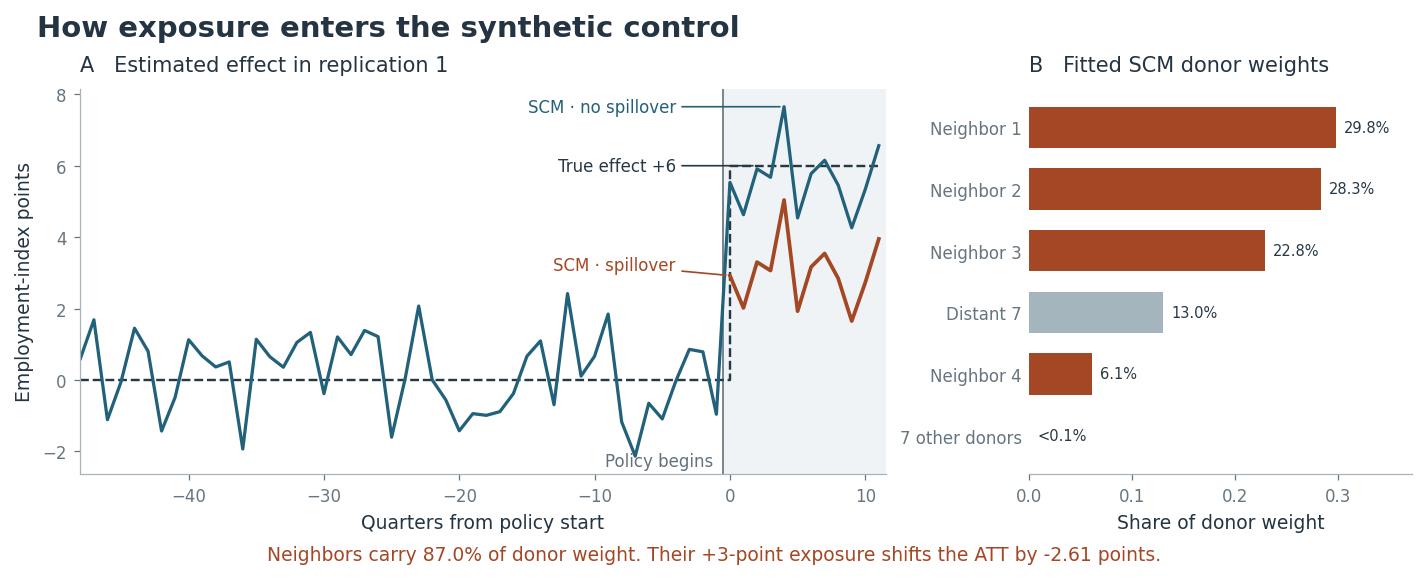

In [5]:
blue, orange, ink, muted = "#21617A", "#A44724", "#273845", "#61727E"
first = draws.query("replication == 1 and method == 'Outcome SCM' and donor_pool == 'All donors'").iloc[0]

with publication_style():
    fig, (trajectory, allocation) = plt.subplots(
        1, 2, figsize=(9.4, 3.75), width_ratios=(2.1, 1), layout="constrained",
    )
    fig.suptitle("How exposure enters the synthetic control", x=0.02, ha="left",
                 fontsize=14, fontweight="semibold")
    trajectory.set_title("A   Estimated effect in replication 1", loc="left", pad=9)
    trajectory.axvspan(-0.5, N_POST - 0.5, color="#EFF3F5", zorder=0)
    trajectory.axvline(-0.5, color=muted, lw=0.8)
    trajectory.step(TIME, paths.true_effect, where="post", color=ink,
                    linestyle="--", lw=1.15, label="True effect")
    trajectory.plot(TIME, paths.scm_clean_effect, color=blue, lw=1.55,
                    label="SCM · no spillover")
    trajectory.plot(TIME[N_PRE:], paths.scm_spillover_effect.iloc[N_PRE:],
                    color=orange, lw=1.8, label="SCM · spillover")
    trajectory.set(xlim=(-N_PRE, N_POST - 0.5), xlabel="Quarters from policy start",
                   ylabel="Employment-index points")
    trajectory.annotate("Policy begins", xy=(-0.5, 0.02), xycoords=("data", "axes fraction"),
                        xytext=(-5, 0), textcoords="offset points", ha="right", color=muted,
                        fontsize=8)
    peak_time = paths.scm_clean_effect.iloc[N_PRE:].idxmax()
    curve_labels = [
        ("SCM · no spillover", peak_time, paths.scm_clean_effect.loc[peak_time],
         paths.scm_clean_effect.loc[peak_time], blue),
        (f"True effect +{TRUE_ATT:.0f}", 2, TRUE_ATT, TRUE_ATT, ink),
        ("SCM · spillover", 0, paths.scm_spillover_effect.loc[0],
         paths.scm_spillover_effect.loc[0] + 0.3, orange),
    ]
    for text, target_x, target_y, label_y, color in curve_labels:
        trajectory.annotate(
            text, xy=(target_x, target_y), xytext=(-4, label_y), ha="right", va="center",
            fontsize=8, color=color, bbox=dict(facecolor="white", edgecolor="none", pad=1),
            arrowprops=dict(arrowstyle="-", color=color, lw=0.8),
        )

    allocation.set_title("B   Fitted SCM donor weights", loc="left", pad=9)
    ordered = weights[weights > 1e-6].sort_values(ascending=False)
    small = weights[weights <= 1e-6]
    if len(small):
        ordered.loc[f"{len(small)} other donors"] = small.sum()
    neighbor = ordered.index.isin(NEAR)
    allocation.barh(range(len(ordered)), ordered, height=0.67,
                    color=np.where(neighbor, orange, "#A4B5BE"))
    for y, value in enumerate(ordered):
        label = "<0.1%" if 0 < value < 0.001 else f"{value:.1%}"
        allocation.annotate(label, (value, y), xytext=(4, 0), textcoords="offset points",
                            va="center", fontsize=7, color=ink)
    allocation.set_yticks(range(len(ordered)), ordered.index, fontsize=8)
    allocation.invert_yaxis()
    allocation.set_xlabel("Share of donor weight")
    allocation.set_xlim(0, 1.25 * ordered.max())
    allocation.spines["left"].set_visible(False)
    allocation.tick_params(axis="y", length=0)

    # This identity concerns the two estimates from this particular realization.
    fig.supxlabel(
        f"Neighbors carry {first.neighbor_weight:.1%} of donor weight. "
        f"Their +{SPILLOVER:.0f}-point exposure shifts the ATT by {first.paired_att_shift:+.2f} points.",
        color=orange, fontsize=9,
    )
    save_figure(fig, out / "spillover-mechanism")
    display(fig)
    plt.close(fig)

## Pretreatment fit and treatment-effect accuracy

Bias is estimated ATT minus the known +6-point effect. The simulation averages equally over independent economies. Whiskers show approximate 95% Monte Carlo intervals for the **mean bias**, calculated as the mean ± 1.96 times its Monte Carlo standard error. The paired-shift standard error uses the within-economy difference. The exported summary also gives the across-economy root mean squared ATT error.

In [6]:
def mcse(values):
    return values.std(ddof=1) / np.sqrt(len(values))


summary_rows = []
for (method, pool), group in draws.groupby(["method", "donor_pool"], sort=False):
    clean_error = group.att_clean - group.true_att
    spill_error = group.att_spillover - group.true_att
    summary_rows.append({
        "method": method, "donor_pool": pool, "replications": len(group),
        "mean_validation_rmse": group.validation_rmse.mean(),
        "mean_neighbor_weight": group.neighbor_weight.mean(),
        "mean_bias_clean": clean_error.mean(), "mcse_bias_clean": mcse(clean_error),
        "mean_bias_spillover": spill_error.mean(), "mcse_bias_spillover": mcse(spill_error),
        "att_rmse_clean": np.sqrt(np.mean(clean_error**2)),
        "att_rmse_spillover": np.sqrt(np.mean(spill_error**2)),
        "mean_paired_shift": group.paired_att_shift.mean(),
        "mcse_paired_shift": mcse(group.paired_att_shift),
    })
order = pd.MultiIndex.from_product([METHODS, POOLS], names=["method", "donor_pool"])
summary = pd.DataFrame(summary_rows).set_index(["method", "donor_pool"]).loc[order]
summary.to_csv(out / "monte-carlo-summary.csv")

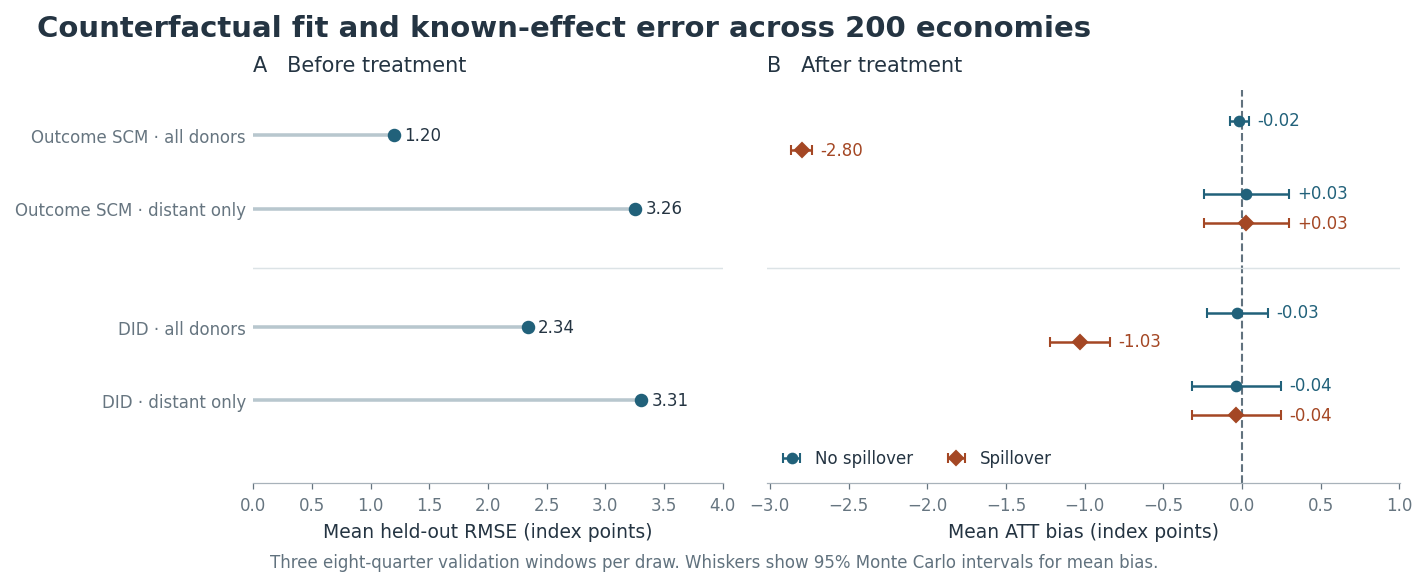

In [7]:
with publication_style():
    fig, (validation_ax, bias_ax) = plt.subplots(
        1, 2, figsize=(9.4, 3.8), width_ratios=(1, 1.35), layout="constrained",
    )
    fig.suptitle(f"Counterfactual fit and known-effect error across {N_REPLICATIONS} economies",
                 x=0.02, ha="left", fontsize=14, fontweight="semibold")
    positions = np.array([3.4, 2.6, 1.3, 0.5])
    row_names = [f"{method} · {pool.lower()}" for method, pool in summary.index]
    validation_ax.set_title("A   Before treatment", loc="left", pad=9)
    validation_ax.hlines(positions, 0, summary.mean_validation_rmse, color="#B8C7CE", lw=1.7)
    validation_ax.scatter(summary.mean_validation_rmse, positions, color=blue, s=30, zorder=3)
    for y, value in zip(positions, summary.mean_validation_rmse):
        validation_ax.annotate(f"{value:.2f}", (value, y), xytext=(5, 0),
                               textcoords="offset points", va="center", fontsize=8)
    validation_ax.set_yticks(positions, row_names)
    validation_ax.set_xlim(0, 1.21 * summary.mean_validation_rmse.max())
    validation_ax.set_xlabel("Mean held-out RMSE (index points)")

    bias_ax.set_title("B   After treatment", loc="left", pad=9)
    bias_ax.axvline(0, lw=1, ls="--", color=muted)
    for regime, label, color, marker, offset in (
        ("clean", "No spillover", blue, "o", 0.16),
        ("spillover", "Spillover", orange, "D", -0.16),
    ):
        bias = summary[f"mean_bias_{regime}"]
        half_width = 1.96 * summary[f"mcse_bias_{regime}"]
        bias_ax.errorbar(bias, positions + offset, xerr=half_width, fmt=marker,
                         color=color, ms=4.6, lw=1.2, capsize=2.5, label=label)
        for y, mean, width in zip(positions + offset, bias, half_width):
            bias_ax.annotate(f"{mean:+.2f}", (mean + width, y), xytext=(4, 0),
                             textcoords="offset points", va="center", color=color, fontsize=8)
    bias_ax.set_xlabel("Mean ATT bias (index points)")
    bias_ax.set_yticks([])
    bias_ax.legend(loc="lower left", ncol=2, fontsize=8, handlelength=1.2)
    bias_ax.set_xlim(right=max(0.8, bias_ax.get_xlim()[1] + 0.55))
    for ax in (validation_ax, bias_ax):
        ax.set_ylim(-0.4, 3.9)
        ax.axhline(1.95, color="#DCE3E6", lw=0.7)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)
    fig.supxlabel("Three eight-quarter validation windows per draw. Whiskers show 95% Monte Carlo intervals for mean bias.",
                  fontsize=8, color=muted)
    save_figure(fig, out / "validation-and-effect-bias")
    display(fig)
    plt.close(fig)

In [8]:
all_scm = summary.loc[("Outcome SCM", "All donors")]
far_scm = summary.loc[("Outcome SCM", "Distant only")]
all_did = summary.loc[("DID", "All donors")]
display(Markdown(
    f"Full-pool SCM assigned **{all_scm.mean_neighbor_weight:.1%}** of donor weight "
    f"to neighbors on average. Its average held-out RMSE was **{all_scm.mean_validation_rmse:.2f}** "
    f"points, compared with **{far_scm.mean_validation_rmse:.2f}** after the prespecified exclusion. "
    f"Spillover shifted its ATT by **{all_scm.mean_paired_shift:+.2f}** points on average "
    f"(paired MCSE {all_scm.mcse_paired_shift:.3f}). Under DID the shift was "
    f"**{all_did.mean_paired_shift:+.2f}** because neighbors always receive four of twelve equal weights. "
    "Excluding neighbors removes their direct exposure but also removes information about the local cycle. "
    "In an observational study, choosing an exclusion like this requires substantive evidence about exposure."
))

display(summary[
    ["mean_neighbor_weight", "att_rmse_clean", "att_rmse_spillover",
     "mean_paired_shift", "mcse_paired_shift"]
].rename(columns={
    "mean_neighbor_weight": "Mean neighbor weight",
    "att_rmse_clean": "ATT RMSE · no spillover", "att_rmse_spillover": "ATT RMSE · spillover",
    "mean_paired_shift": "Paired ATT shift", "mcse_paired_shift": "MCSE of shift",
}).round(3))

Full-pool SCM assigned **92.7%** of donor weight to neighbors on average. Its average held-out RMSE was **1.20** points, compared with **3.26** after the prespecified exclusion. Spillover shifted its ATT by **-2.78** points on average (paired MCSE 0.013). Under DID the shift was **-1.00** because neighbors always receive four of twelve equal weights. Excluding neighbors removes their direct exposure but also removes information about the local cycle. In an observational study, choosing an exclusion like this requires substantive evidence about exposure.

Mean neighbor weight  ATT RMSE · no spillover  \
method      donor_pool                                                    
Outcome SCM All donors                   0.927                    0.445   
            Distant only                 0.000                    1.947   
DID         All donors                   0.333                    1.379   
            Distant only                 0.000                    2.038   

                          ATT RMSE · spillover  Paired ATT shift  \
method      donor_pool                                             
Outcome SCM All donors                   2.837            -2.781   
            Distant only                 1.947             0.000   
DID         All donors                   1.720            -1.000   
            Distant only                 2.038             0.000   

                          MCSE of shift  
method      donor_pool                   
Outcome SCM All donors            0.013  
            Distant only          0.000  
DID         All donors            0.000  
            Distant only          0.000